# HBM Test on Murine OAZ1

In [1]:
# Library Imports
from HBM_core import *
from MARTA_Core import *
import os
# For reproducibility, forces each chain to use one thread only -> should help getting same results
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

## SETUP

In [86]:
# Load data
df = pd.read_csv("/.../ENSMUST00000180036_raw_counts.csv")
metadata = pd.read_csv("/../Mouse_metadata.csv")
coordinates = {"x_slice": (100, 254), "y_slice": (304, 733), "n_slice": (850, 920)}
outpath = ""
gene = "OAZ1"
# Selects factor (eg. TISSUE) to group datasets by. Sets min number runs per group (eg. 10 or more)
factor = "TISSUE"
min_members = 10

# Sets random state (for reproducibility)
random_state = 42

In [3]:
df.shape

(1044, 153)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_factor_logit, sigma_factor, theta_run_logit_offset]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 17 seconds.
Sampling: [Y_obs, mu_factor_logit, sigma_factor, theta_run_logit_offset]


===== PRIOR PREDICTIVE ON EFFICIENCIES (probability scale) =====

Group-level prior (mu_factor, shared across all levels):
  median = 0.0993    95% CI = [0.0151, 0.4302]

Run-level prior (theta_run) by level:
Level                    median                    95% CI
---------------------------------------------------------
Pancreas                 0.1006          [0.0066, 0.6471]
Brain                    0.0980          [0.0070, 0.6407]
Bone                     0.0975          [0.0067, 0.6606]
Heart                    0.1046          [0.0065, 0.6608]
Liver                    0.1013          [0.0066, 0.6481]
Embryo                   0.0994          [0.0063, 0.6414]
Lung                     0.0955          [0.0061, 0.6441]
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Shrinkage/Prior_predictive_checks.txt
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Shrinkage/Prior_predictive_efficiencies.png


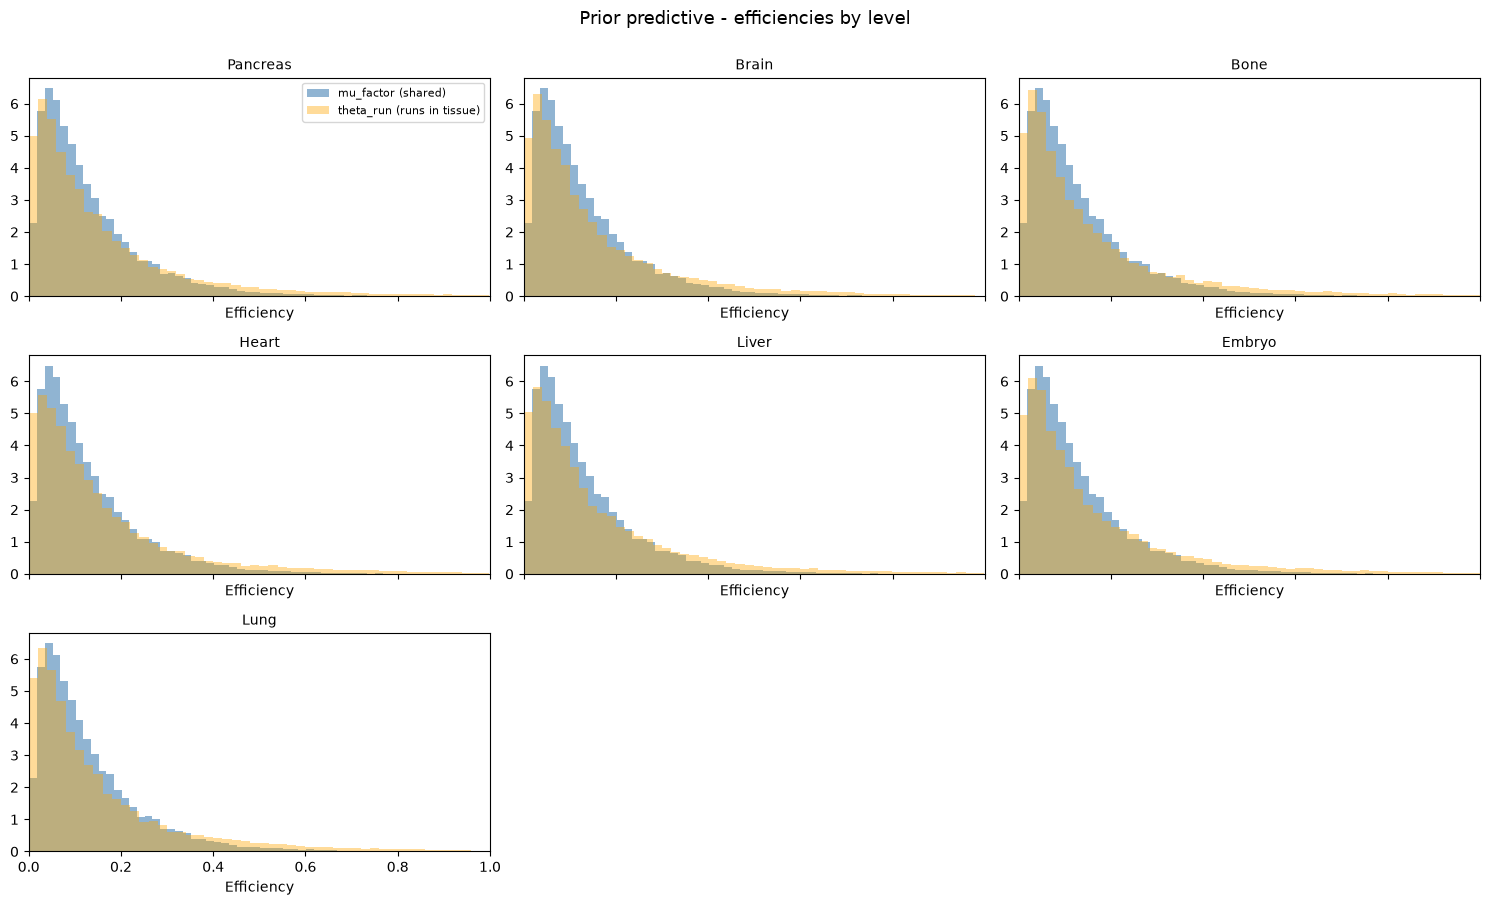

=== MCMC Diagnostics (thresholds: R̂ < 1.01, ESS ≥ 400) ===
✓ All diagnostics passed.
Divergent transitions: 0
No divergent transitions (0 / 8000 draws).
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Shrinkage/model_diagnostics.txt


Sampling: [Y_obs]


Output()

  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Shrinkage/convergence_trace_plots.png


======== POSTERIOR PREDICTIVE CHECKS ========
mean      T(y_obs)=    167.13   p_B=0.887
sd        T(y_obs)=    320.59   p_B=0.478
min       T(y_obs)=      1.00   p_B=0.710
max       T(y_obs)=   3216.00   p_B=0.374
q25       T(y_obs)=     25.50   p_B=0.867
median    T(y_obs)=     86.00   p_B=0.530
q75       T(y_obs)=    209.50   p_B=0.846


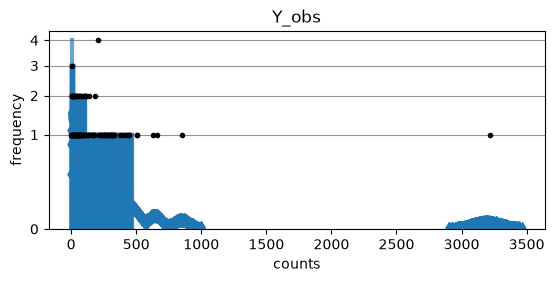

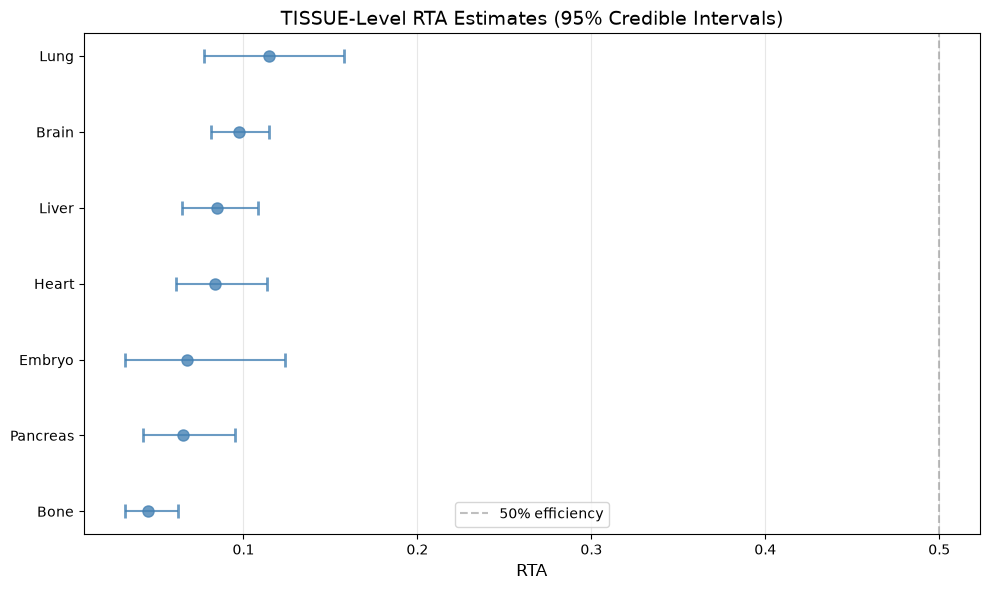

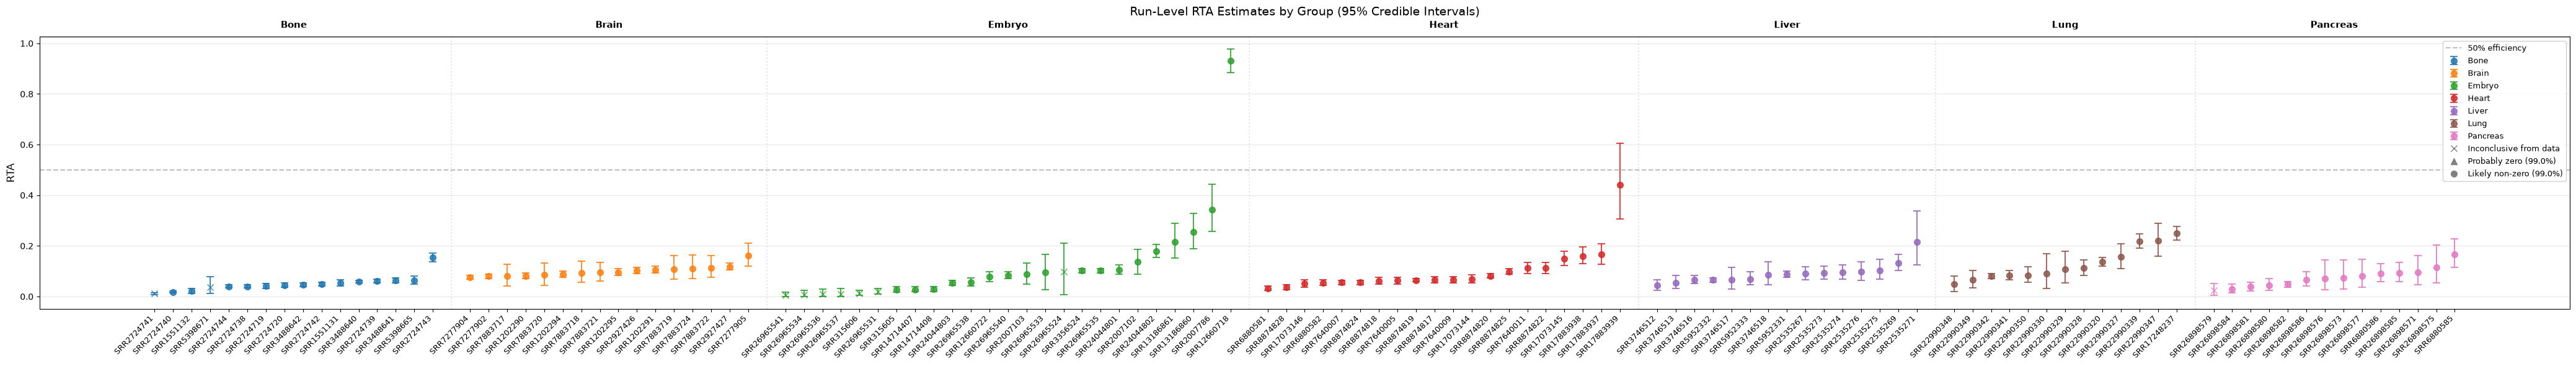

In [4]:
res, runs, summary = run_HBM(df, metadata, coordinates, factor, outpath, random_state = 42, min_members = 10, mass_threshold = 0.99, belief = "moderate")

#  SHRINKAGE PLOTS

In this section, we compare the "MARTA" efficiency (-> the one computed by MARTA) to the HBM's values. We could also just compare the "Naive" one...


In [5]:
runs_to_do = runs["Run"].values
df = df[runs_to_do]
df

,SRR22990329,SRR26965533,SRR17073145,SRR13186861,SRR17883937,SRR17883939,SRR5398671,SRR26965524,SRR22990347,SRR2007786,...,SRR8874822,SRR2927427,SRR6880581,SRR26965537,SRR8874817,SRR3746513,SRR8874825,SRR26965538,SRR1202290,SRR315606
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1039,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1040,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1041,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1042,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
df
x_avg = df.iloc[coordinates["x_slice"][0]:coordinates["x_slice"][1]].mean(axis=0)
y_avg = df.iloc[coordinates["y_slice"][0]:coordinates["y_slice"][1]].mean(axis=0)
n_avg = df.iloc[coordinates["n_slice"][0]:coordinates["n_slice"][1]].mean(axis=0)

In [7]:

efficiency_old = (y_avg)/(x_avg)

efficiency_old

SRR22990329    0.151567
SRR26965533    0.412202
SRR17073145    0.150916
SRR13186861    0.218750
SRR17883937    0.169516
                 ...   
SRR3746513     0.046205
SRR8874825     0.102094
SRR26965538    0.062250
SRR1202290     0.085079
SRR315606      0.026347
Length: 119, dtype: float64

In [12]:
df_small = runs[["Run", "Mean RTA", "total_counts", "level"]].copy()
df_small["eff_old_method"] = df_small["Run"].map(efficiency_old)
df_small.to_csv(outpath + "/Shrinkage_plot_data.csv")
df_small

,Run,Mean RTA,total_counts,level,eff_old_method
59,SRR22990329,0.108933,64.0,Lung,0.151567
103,SRR26965533,0.095991,623.0,Embryo,0.412202
64,SRR17073145,0.149087,348.0,Heart,0.150916
62,SRR13186861,0.216744,103.0,Embryo,0.218750
70,SRR17883937,0.165767,212.0,Heart,0.169516
...,...,...,...,...,...
40,SRR3746513,0.054237,114.0,Liver,0.046205
39,SRR8874825,0.098434,1400.0,Heart,0.102094
37,SRR26965538,0.056301,406.0,Embryo,0.062250
36,SRR1202290,0.082064,1190.0,Brain,0.085079


In [11]:
import plotly.express as px

fig = px.scatter(
    df_small,
    x="eff_old_method",
    y="Mean RTA",
    color="level",
    hover_data={"Run": True, "level": True, "total_counts": True,
                "eff_old_method": ":.4f", "Mean RTA": ":.4f"},
    labels={"level": "Tissue",
        "eff_old_method": "Naive efficiency estimate",
            "Mean RTA": "HBM-inferred mean efficiency"},
    title="Shrinkage plot — " + gene,
    opacity=0.85,
)

# Diagonal reference line
max_val = max(df_small["eff_old_method"].max(), df_small["Mean RTA"].max()) * 1.05
fig.add_shape(type="line", x0=0, y0=0, x1=max_val, y1=max_val,
              line=dict(color="gray", dash="dash"))

fig.update_traces(marker=dict(size=9))
fig.update_layout()
fig.update_layout(
    plot_bgcolor="white",
    paper_bgcolor="white",
    font=dict(family="Times New Roman, DejaVu Serif, Bitstream Vera Serif, serif",
    size=14, color="black"),
    title_font=dict(size=22),
    legend_title_font=dict(size=16),
    legend_font=dict(size=14)     ,
    legend_title_text="Tissue",
    width=1000,
    height=1000
)

axis_style = dict(
    title_font=dict(size=18),
    tickfont=dict(size=14),
    showgrid=True,
    gridcolor="#c7c5c5",
    gridwidth=0.7,
    griddash = "dot",
    zeroline=False,
    linecolor="gray",
    ticks="outside"
)
fig.update_xaxes(**axis_style)
fig.update_yaxes(**axis_style)

fig.update_layout(
    legend=dict(
        x=0.02,
        y=0.98,
        xanchor="left",
        yanchor="top",
        bgcolor="white",
        bordercolor="gray",
        borderwidth=1
    )
)

outpath_full = outpath + "/Shrinkage_plot.svg"
outpath_full_html = outpath + "/Shrinkage_plot.html"
outpath_full_png = outpath + "/Shrinkage_plot.png"
fig.write_image(outpath_full, width=800, height=500)
fig.write_html(outpath_full_html)
fig.write_image(outpath_full_png, width=800, height=500)

fig.show()

# PRIOR SENSITIVITY CHECK

Here is the code that compares theestimates across the three belief regimes.

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_factor_logit, sigma_factor, theta_run_logit_offset]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 16 seconds.
Sampling: [Y_obs, mu_factor_logit, sigma_factor, theta_run_logit_offset]


===== PRIOR PREDICTIVE ON EFFICIENCIES (probability scale) =====

Group-level prior (mu_factor, shared across all levels):
  median = 0.0993    95% CI = [0.0151, 0.4302]

Run-level prior (theta_run) by level:
Level                    median                    95% CI
---------------------------------------------------------
Pancreas                 0.1006          [0.0066, 0.6471]
Brain                    0.0980          [0.0070, 0.6407]
Bone                     0.0975          [0.0067, 0.6606]
Heart                    0.1046          [0.0065, 0.6608]
Liver                    0.1013          [0.0066, 0.6481]
Embryo                   0.0994          [0.0063, 0.6414]
Lung                     0.0955          [0.0061, 0.6441]
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/Prior_predictive_checks.txt
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/Prior_predictive_efficiencies

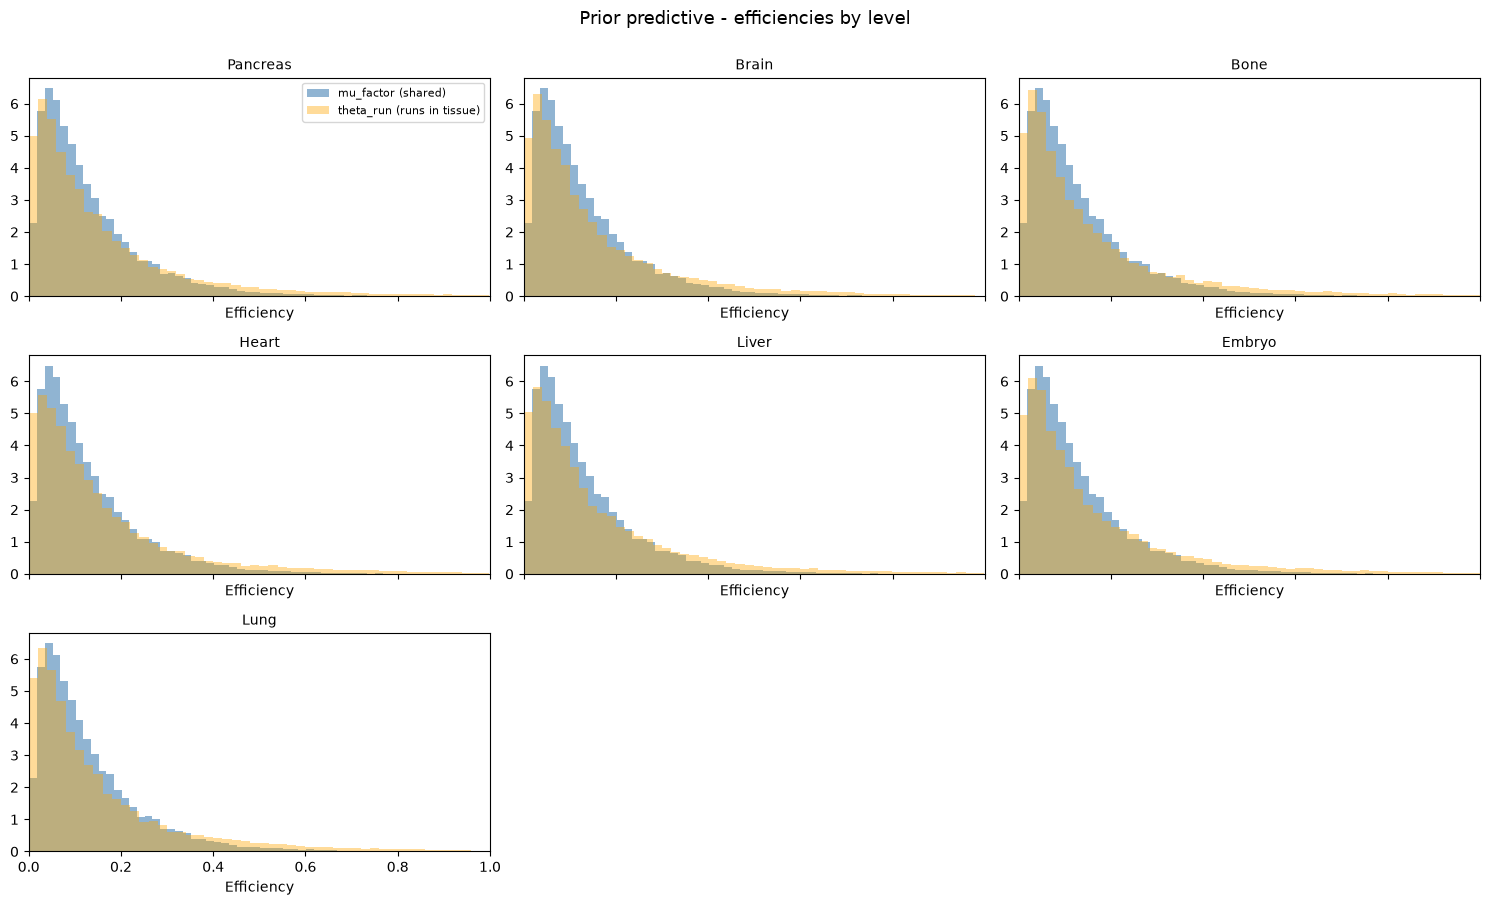

=== MCMC Diagnostics (thresholds: R̂ < 1.01, ESS ≥ 400) ===
✓ All diagnostics passed.
Divergent transitions: 0
No divergent transitions (0 / 8000 draws).
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/model_diagnostics.txt


Sampling: [Y_obs]


Output()

  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/convergence_trace_plots.png


======== POSTERIOR PREDICTIVE CHECKS ========
mean      T(y_obs)=    167.13   p_B=0.887
sd        T(y_obs)=    320.59   p_B=0.478
min       T(y_obs)=      1.00   p_B=0.710
max       T(y_obs)=   3216.00   p_B=0.374
q25       T(y_obs)=     25.50   p_B=0.867
median    T(y_obs)=     86.00   p_B=0.530
q75       T(y_obs)=    209.50   p_B=0.846


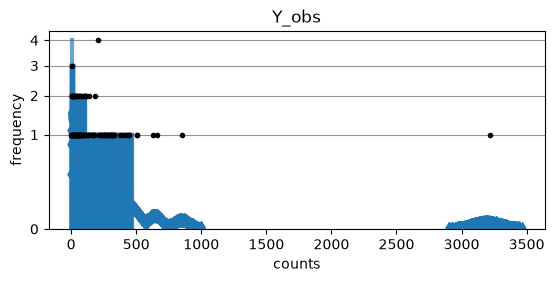

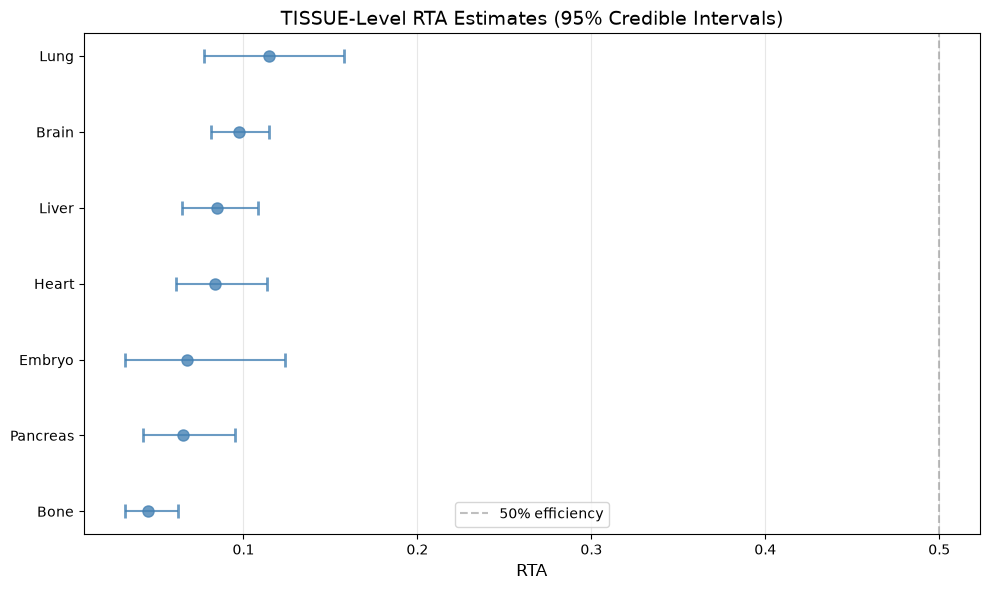

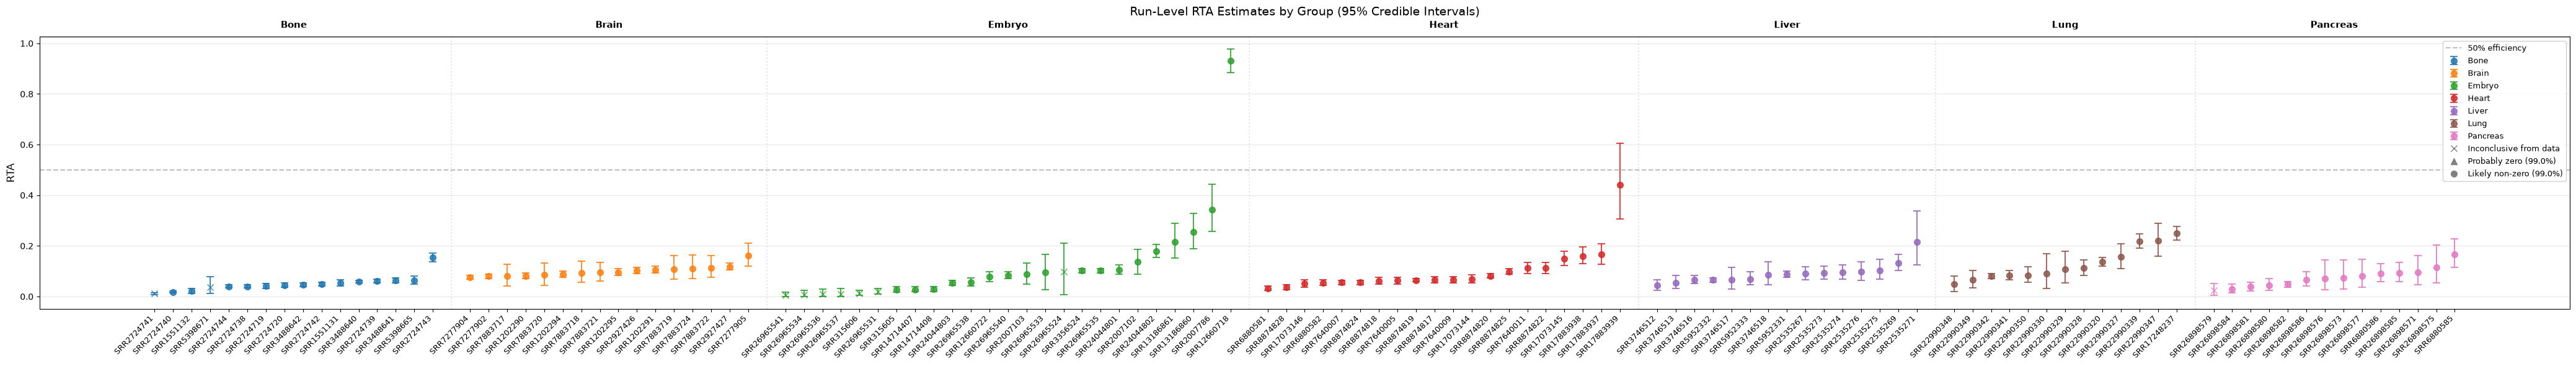

In [87]:
res, runs, summary = run_HBM(df, metadata, coordinates, factor, outpath, random_state = 42, min_members = 10, mass_threshold = 0.99, belief = "moderate")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_factor_logit, sigma_factor, theta_run_logit_offset]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 15 seconds.
Sampling: [Y_obs, mu_factor_logit, sigma_factor, theta_run_logit_offset]


===== PRIOR PREDICTIVE ON EFFICIENCIES (probability scale) =====

Group-level prior (mu_factor, shared across all levels):
  median = 0.2678    95% CI = [0.0332, 0.7863]

Run-level prior (theta_run) by level:
Level                    median                    95% CI
---------------------------------------------------------
Pancreas                 0.2715          [0.0159, 0.8875]
Brain                    0.2641          [0.0177, 0.8843]
Bone                     0.2625          [0.0166, 0.8965]
Heart                    0.2817          [0.0162, 0.8955]
Liver                    0.2744          [0.0167, 0.8868]
Embryo                   0.2683          [0.0161, 0.8909]
Lung                     0.2571          [0.0154, 0.8880]
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/Prior_predictive_checks.txt
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/Prior_predictive_efficiencies

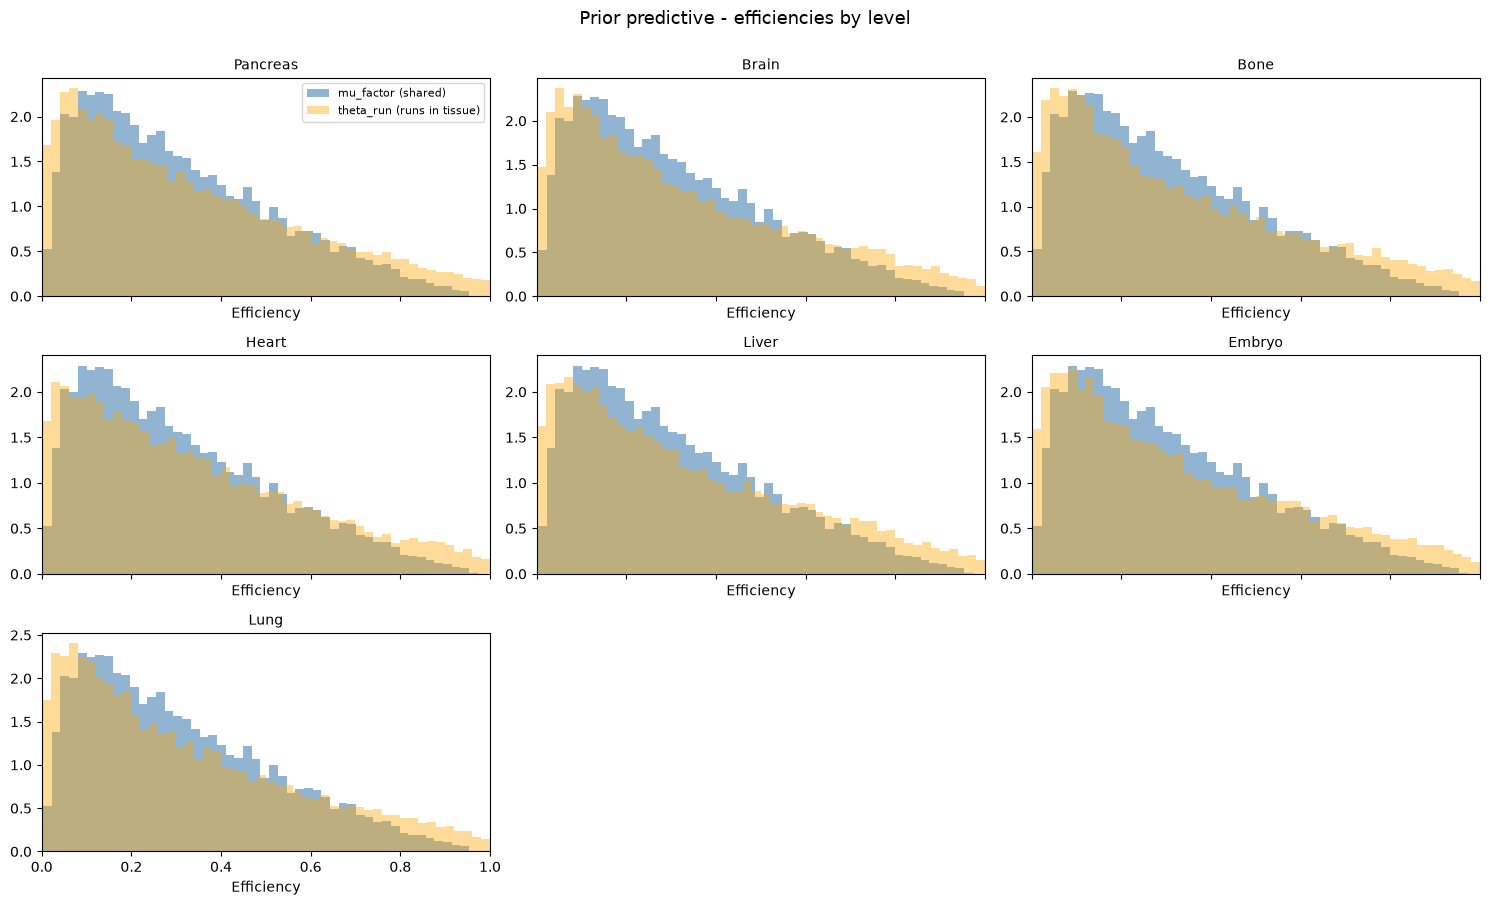

=== MCMC Diagnostics (thresholds: R̂ < 1.01, ESS ≥ 400) ===
✓ All diagnostics passed.
Divergent transitions: 0
No divergent transitions (0 / 8000 draws).
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/model_diagnostics.txt


Sampling: [Y_obs]


Output()

  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/convergence_trace_plots.png


======== POSTERIOR PREDICTIVE CHECKS ========
mean      T(y_obs)=    167.13   p_B=0.893
sd        T(y_obs)=    320.59   p_B=0.482
min       T(y_obs)=      1.00   p_B=0.705
max       T(y_obs)=   3216.00   p_B=0.387
q25       T(y_obs)=     25.50   p_B=0.871
median    T(y_obs)=     86.00   p_B=0.539
q75       T(y_obs)=    209.50   p_B=0.846


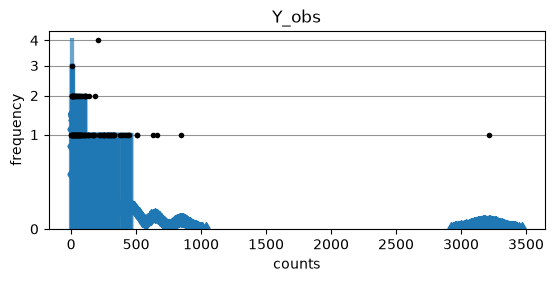

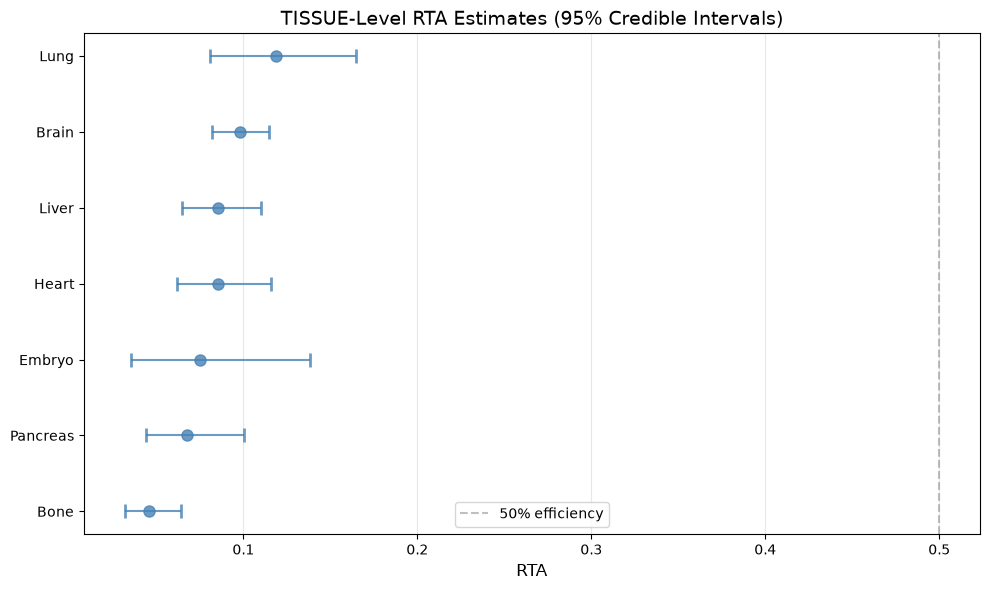

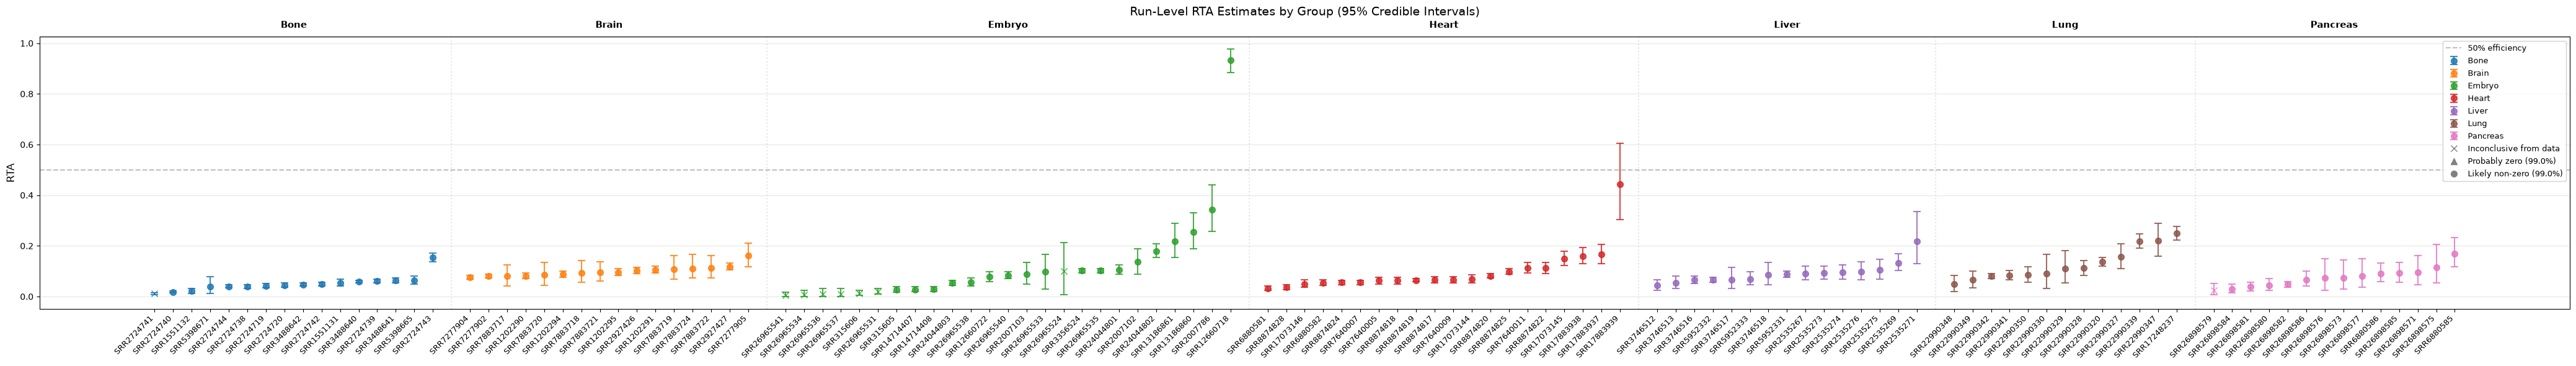

In [89]:
res2, runs2, summary2 = run_HBM(df, metadata, coordinates, factor, outpath, random_state = 42, min_members = 10, mass_threshold = 0.99, belief = "frequent")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_factor_logit, sigma_factor, theta_run_logit_offset]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 16 seconds.
Sampling: [Y_obs, mu_factor_logit, sigma_factor, theta_run_logit_offset]


===== PRIOR PREDICTIVE ON EFFICIENCIES (probability scale) =====

Group-level prior (mu_factor, shared across all levels):
  median = 0.0099    95% CI = [0.0005, 0.1517]

Run-level prior (theta_run) by level:
Level                    median                    95% CI
---------------------------------------------------------
Pancreas                 0.0101          [0.0003, 0.2481]
Brain                    0.0097          [0.0003, 0.2454]
Bone                     0.0095          [0.0003, 0.2814]
Heart                    0.0108          [0.0003, 0.2749]
Liver                    0.0103          [0.0003, 0.2462]
Embryo                   0.0099          [0.0003, 0.2666]
Lung                     0.0093          [0.0003, 0.2556]
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/Prior_predictive_checks.txt
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/Prior_predictive_efficiencies

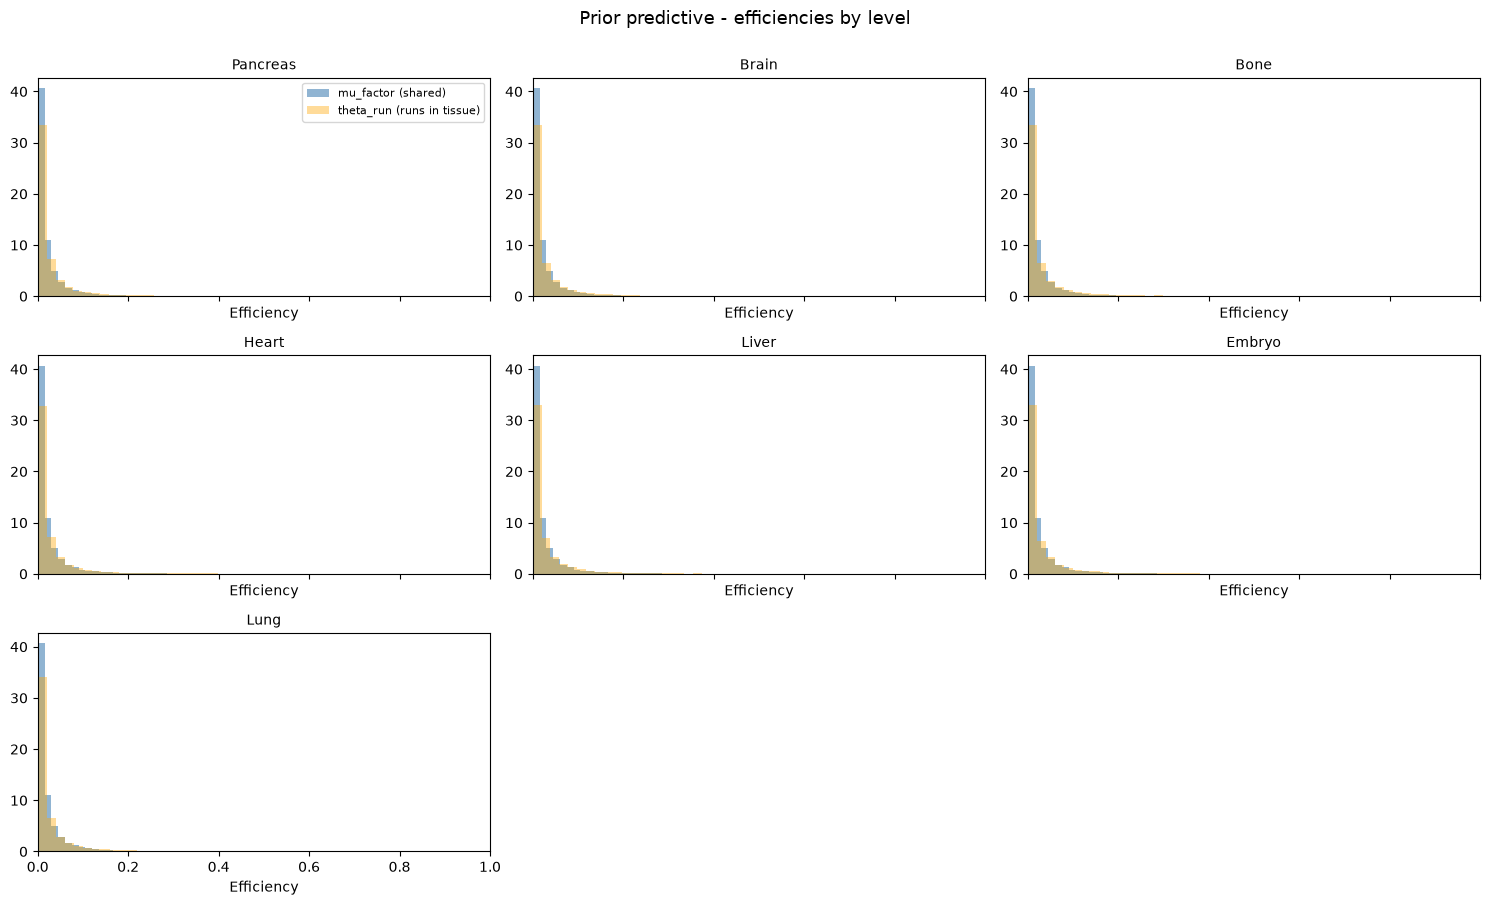

=== MCMC Diagnostics (thresholds: R̂ < 1.01, ESS ≥ 400) ===
✓ All diagnostics passed.
Divergent transitions: 0
No divergent transitions (0 / 8000 draws).
  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/model_diagnostics.txt


Sampling: [Y_obs]


Output()

  Saved to: /home/gionmattia/Desktop/HBM/Murine_OAZ1/Results/Moderate_belief_Poisson/Sensitivity_Analysis/convergence_trace_plots.png


======== POSTERIOR PREDICTIVE CHECKS ========
mean      T(y_obs)=    167.13   p_B=0.872
sd        T(y_obs)=    320.59   p_B=0.470
min       T(y_obs)=      1.00   p_B=0.688
max       T(y_obs)=   3216.00   p_B=0.366
q25       T(y_obs)=     25.50   p_B=0.858
median    T(y_obs)=     86.00   p_B=0.519
q75       T(y_obs)=    209.50   p_B=0.843


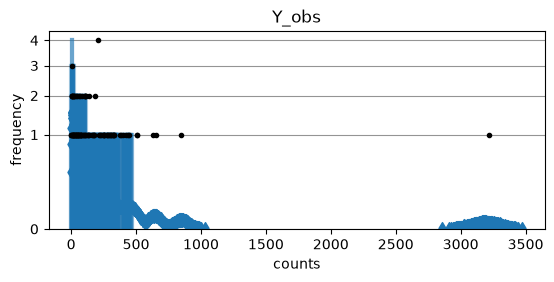

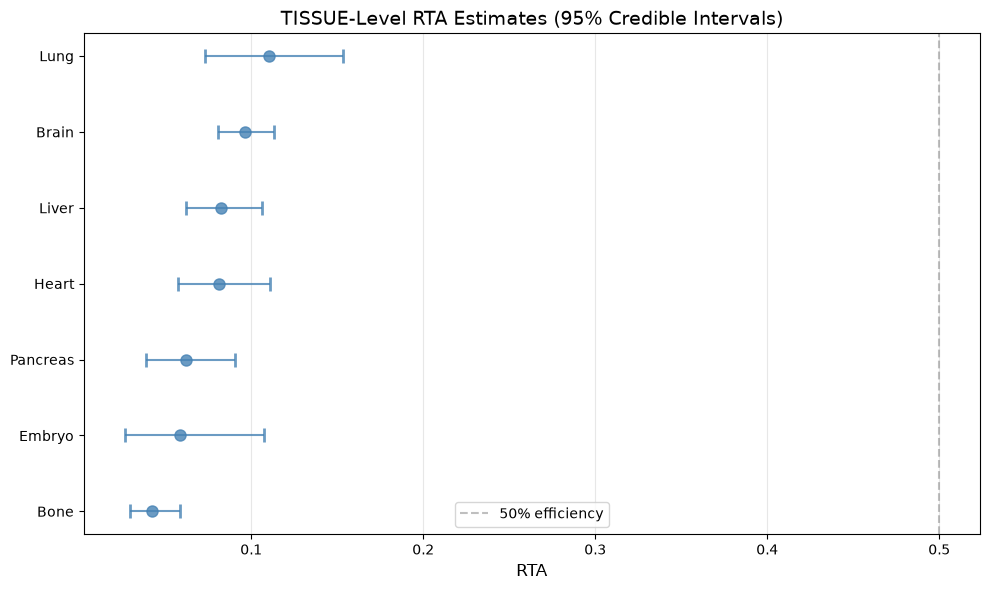

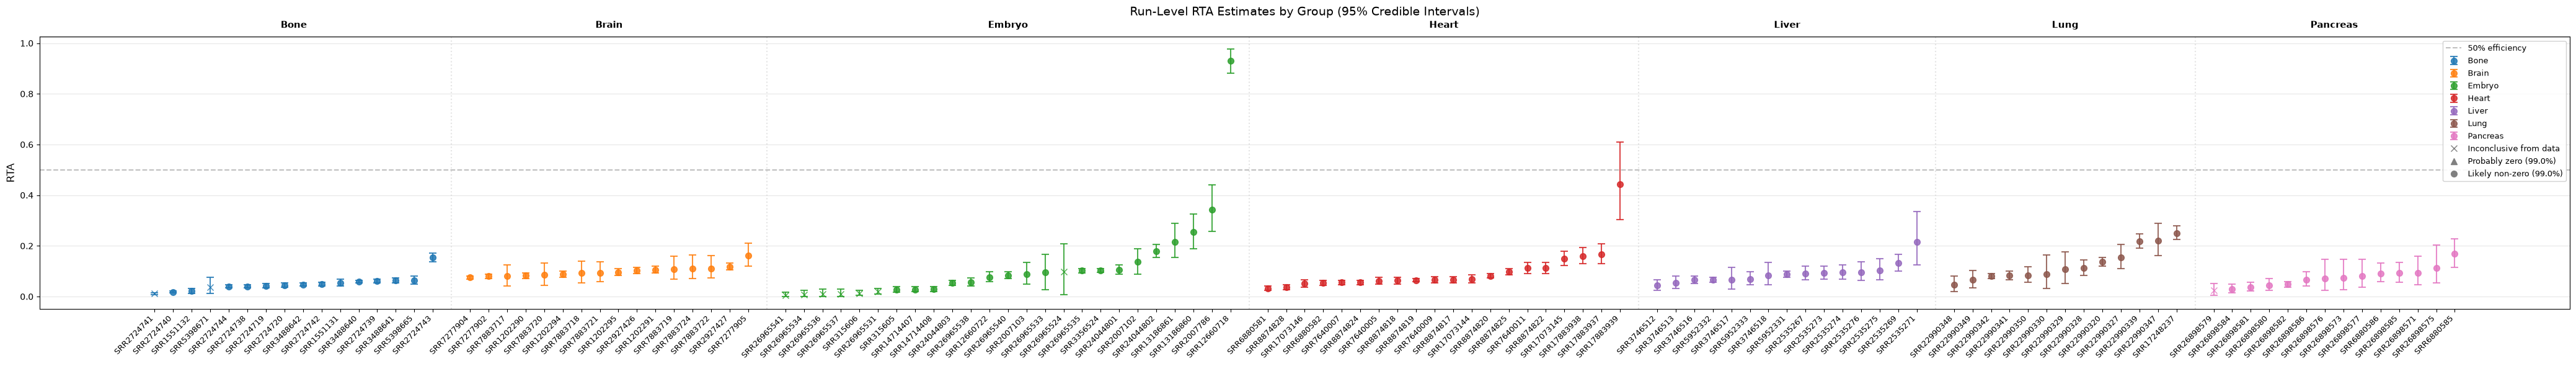

In [90]:
res3, runs3, summary3 = run_HBM(df, metadata, coordinates, factor, outpath, random_state = 42, min_members = 10, mass_threshold = 0.99, belief = "rare")